# Lab 3: K-Nearest Neighbors (KNN) Classification & Regression
## Non-Parametric Learning, Distance Metric Space, Decision Boundaries & Bias-Variance Dynamics

**Course:** M.Tech Machine Learning Laboratory  
**Topic:** Instance-Based Lazy Learning, Distance Metrics, Boundary Smoothing & Tradeoff Analysis  
**Target Notebook:** `lab_3/KNN.ipynb`  

---

## Theoretical Foundations

The **$K$-Nearest Neighbors (KNN)** algorithm, first introduced by *Evelyn Fix and Joseph Hodges (1951)* and expanded by *Thomas Cover and Peter Hart (1967)*, is an archetypal **non-parametric, instance-based "lazy" learning** algorithm. 

Unlike eager learning models (such as Linear Regression or Decision Trees) that construct an explicit global hypothesis during an eager training phase, KNN postpones generalization until an active query point $x_q$ is presented at inference time.

---

### 1. Distance Metric Formulations in $\mathbb{R}^d$

Given two feature vectors $u, v \in \mathbb{R}^d$:

1. **Euclidean Distance ($L_2$ Norm):**
   $$d_2(u, v) = \sqrt{\sum_{i=1}^{d} (u_i - v_i)^2}$$
   * Represents standard straight-line ruler distance. Rotation-invariant, but sensitive to unscaled feature magnitudes.

2. **Manhattan Distance ($L_1$ Norm / City Block):**
   $$d_1(u, v) = \sum_{i=1}^{d} |u_i - v_i|$$
   * Measures grid-aligned coordinate travel. Less sensitive to extreme coordinate outliers than $L_2$.

3. **Minkowski Distance ($L_p$ Metric):**
   $$d_p(u, v) = \left( \sum_{i=1}^{d} |u_i - v_i|^p \right)^{\frac{1}{p}}$$
   * Generalizes $L_1$ ($p=1$) and $L_2$ ($p=2$). For $p \rightarrow \infty$, it converges to Chebyshev distance $\max_i |u_i - v_i|$.

4. **Cosine Distance (Angular Dissimilarity):**
   $$d_{\text{cosine}}(u, v) = 1 - \frac{u \cdot v}{\|u\|_2 \|v\|_2}$$
   * Evaluates directional alignment irrespective of vector magnitude. Commonly utilized in text mining and gene expression.

---

### 2. Decision Rules & Voting Mechanics

For a query point $x_q$, let $\mathcal{N}_K(x_q)$ denote the set of its $K$ nearest training instances:

1. **Standard Majority Voting (Uniform Weighting):**
   $$\hat{y}_q = \arg\max_{c \in \mathcal{C}} \sum_{x_i \in \mathcal{N}_K(x_q)} \mathbb{I}(y_i = c)$$
   where $\mathbb{I}(\cdot)$ is the indicator function. Each neighbor casts an equal vote, regardless of proximity.

2. **Distance-Weighted Voting (Inverse Distance Weighting):**
   $$w_i = \frac{1}{d(x_q, x_i) + \epsilon}$$
   $$\hat{y}_q = \arg\max_{c \in \mathcal{C}} \sum_{x_i \in \mathcal{N}_K(x_q)} w_i \, \mathbb{I}(y_i = c)$$
   where $\epsilon > 0$ is a minute numerical stabilizer. Closer neighbors exert exponentially stronger voting influence.

---

### 3. Computational & Statistical Properties

* **Training Complexity**: $\mathcal{O}(1)$ — Training consists purely of storing the training data.
* **Inference Complexity**: $\mathcal{O}(N \cdot d)$ for brute-force exhaustive search across $N$ training samples of dimension $d$. Scalable to $\mathcal{O}(d \log N)$ using spatial trees ($k$-d trees, Ball trees) for moderate dimensions ($d < 20$).
* **Curse of Dimensionality**: As dimension $d \rightarrow \infty$, the volume of space grows exponentially, causing all sample points to become nearly equidistant, degrading metric discrimination.

---

## 2. Dataset Ingestion, EDA & Strict Featurization Ordering

We benchmark $K$-Nearest Neighbors on the canonical **Fisher's Iris dataset**, consistent with [`decision_tree.ipynb`](file:///c:/Projects/Personal-Projects/ML-MTech-I/lab_3/decision_tree.ipynb).

### Strict Featurization Ordering (ML Best Practice)
KNN distance calculations are critically distorted by differing feature scales. In strict adherence to `@skill:ml-best-practices`:
1. We split the dataset into training ($80\%$) and test ($20\%$) sets **prior** to any data scaling.
2. We fit `StandardScaler` **strictly on training data** and transform test data independently to prevent data leakage.

Iris Dataset Loaded: 150 samples across 4 features.
Target Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


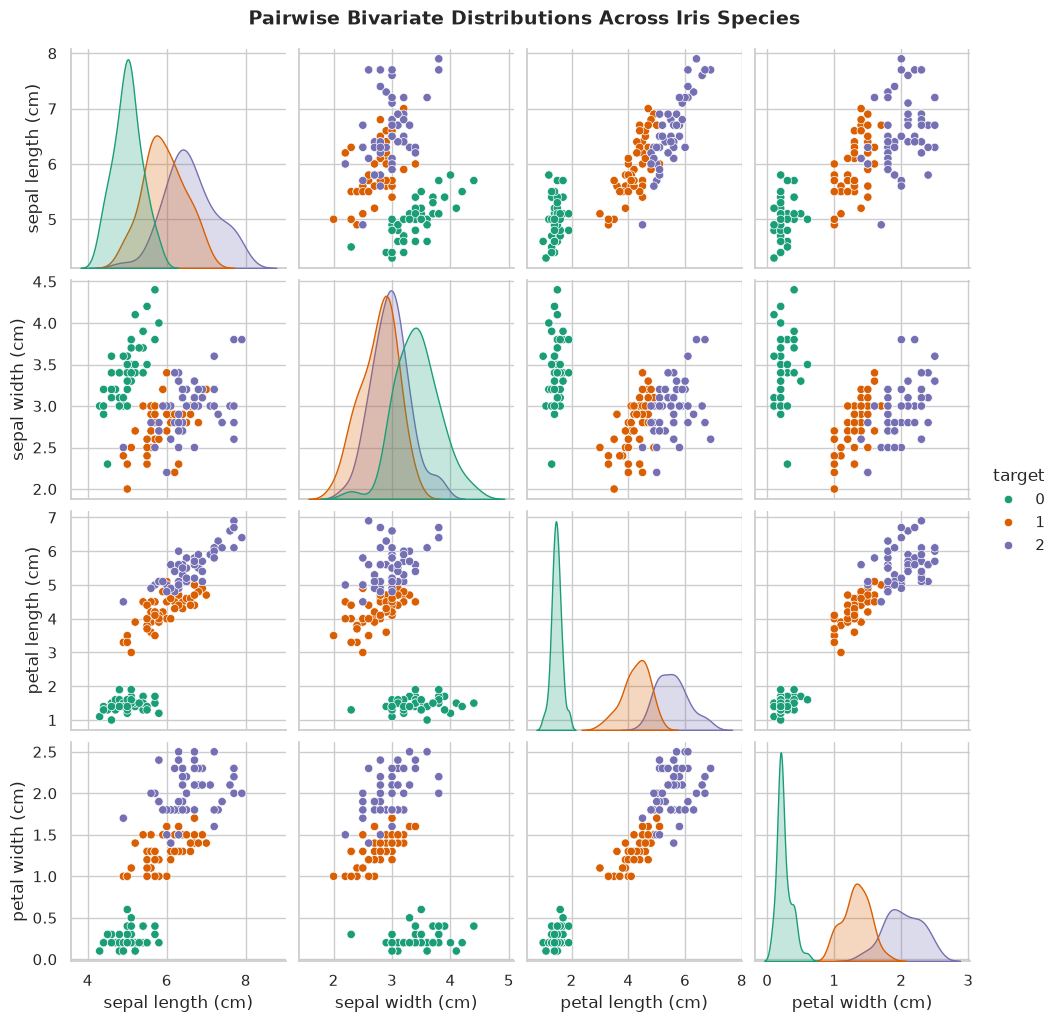

Training Set: 120 samples | Test Set: 30 samples


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set modern plotting theme
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

# Ingest Fisher's Iris Dataset
iris = load_iris(as_frame=True)
df_iris = iris.frame
feature_names = iris.feature_names
target_names = iris.target_names

print(f"Iris Dataset Loaded: {df_iris.shape[0]} samples across {len(feature_names)} features.")
print(f"Target Classes: {list(target_names)}")

# Pairplot feature inspection
sns.pairplot(df_iris, hue='target', palette='Dark2', diag_kind='kde')
plt.suptitle("Pairwise Bivariate Distributions Across Iris Species", y=1.02, fontsize=14, fontweight='bold')
plt.show()

# 1. Stratified Train/Test Split (80% Train, 20% Test) BEFORE featurization
X = df_iris[feature_names].values
y = df_iris['target'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Fit StandardScaler strictly on training set to prevent data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Set: {X_train_scaled.shape[0]} samples | Test Set: {X_test_scaled.shape[0]} samples")

---

## 3. From-Scratch $K$-Nearest Neighbors (`class CustomKNNClassifier`)

We construct a vectorized, pure Python/NumPy implementation of the $K$-Nearest Neighbors classifier supporting Euclidean, Manhattan, and Minkowski distance metrics with both uniform and distance-weighted voting.

In [2]:
from scipy.spatial.distance import cdist

class CustomKNNClassifier:
    """
    From-scratch vectorized implementation of K-Nearest Neighbors Classifier.
    """
    def __init__(self, n_neighbors: int = 5, metric: str = 'euclidean', p: int = 2, weights: str = 'uniform'):
        self.n_neighbors: int = n_neighbors
        self.metric: str = metric
        self.p: int = p
        self.weights: str = weights
        self.X_train_: np.ndarray = None
        self.y_train_: np.ndarray = None
        self.classes_: np.ndarray = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        """Store training samples (lazy learning)."""
        self.X_train_ = np.asarray(X)
        self.y_train_ = np.asarray(y)
        self.classes_ = np.unique(y)
        return self

    def _compute_distances(self, X_query: np.ndarray) -> np.ndarray:
        """Vectorized distance calculation between query points and stored training set."""
        if self.metric == 'euclidean':
            return cdist(X_query, self.X_train_, metric='euclidean')
        elif self.metric == 'manhattan':
            return cdist(X_query, self.X_train_, metric='cityblock')
        elif self.metric == 'minkowski':
            return cdist(X_query, self.X_train_, metric='minkowski', p=self.p)
        else:
            raise ValueError(f"Unsupported metric: {self.metric}")

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        """Estimate class membership probabilities for query samples."""
        distances = self._compute_distances(X)
        n_queries = X.shape[0]
        n_classes = len(self.classes_)
        probas = np.zeros((n_queries, n_classes))

        # Find k nearest neighbors for each query sample
        neighbor_indices = np.argsort(distances, axis=1)[:, :self.n_neighbors]

        for i in range(n_queries):
            k_indices = neighbor_indices[i]
            k_labels = self.y_train_[k_indices]
            k_distances = distances[i, k_indices]

            if self.weights == 'uniform':
                for class_idx, c in enumerate(self.classes_):
                    probas[i, class_idx] = np.mean(k_labels == c)
            elif self.weights == 'distance':
                # Inverse distance weights with numerical epsilon
                weights = 1.0 / (k_distances + 1e-8)
                total_weight = np.sum(weights)
                for class_idx, c in enumerate(self.classes_):
                    class_mask = (k_labels == c)
                    probas[i, class_idx] = np.sum(weights[class_mask]) / total_weight

        return probas

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Predict class labels for query samples."""
        probas = self.predict_proba(X)
        return self.classes_[np.argmax(probas, axis=1)]

print("CustomKNNClassifier class compiled successfully.")

CustomKNNClassifier class compiled successfully.


---

## 4. Hyperparameter Exploration: Bias-Variance Tradeoff Across $K$

The hyperparameter $K$ directly governs model complexity in instance-based learning:
* **Small $K$ (e.g., $K=1$) $\rightarrow$ High Variance / Overfitting**: The decision boundary is highly complex, jagged, and sensitive to sample noise. Training accuracy is $100\%$, but test error is vulnerable to noise.
* **Large $K$ (e.g., $K \rightarrow N$) $\rightarrow$ High Bias / Underfitting**: The decision boundary is excessively smoothed, approaching a naive prior majority-class classifier.

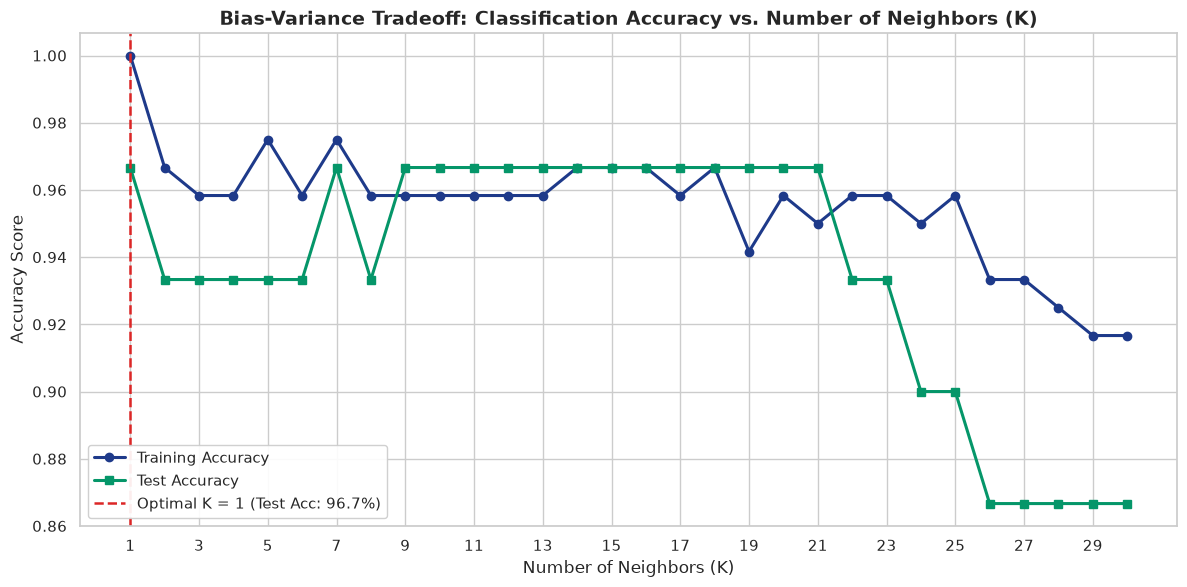

Optimal Hyperparameter Identified: K = 1 with 96.67% Test Accuracy.


In [3]:
from sklearn.metrics import accuracy_score

k_range = range(1, 31)
train_accuracies = []
test_accuracies = []

for k in k_range:
    knn = CustomKNNClassifier(n_neighbors=k, metric='euclidean', weights='uniform')
    knn.fit(X_train_scaled, y_train)
    
    train_acc = accuracy_score(y_train, knn.predict(X_train_scaled))
    test_acc = accuracy_score(y_test, knn.predict(X_test_scaled))
    
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

plt.figure(figsize=(12, 6))
plt.plot(k_range, train_accuracies, marker='o', color='#1e3a8a', linewidth=2.2, label='Training Accuracy')
plt.plot(k_range, test_accuracies, marker='s', color='#059669', linewidth=2.2, label='Test Accuracy')

optimal_k = k_range[int(np.argmax(test_accuracies))]
plt.axvline(x=optimal_k, color='#dc2626', linestyle='--', linewidth=1.8, 
            label=f'Optimal K = {optimal_k} (Test Acc: {max(test_accuracies)*100:.1f}%)')

plt.title("Bias-Variance Tradeoff: Classification Accuracy vs. Number of Neighbors (K)", fontsize=14, fontweight='bold')
plt.xlabel("Number of Neighbors (K)", fontsize=12)
plt.ylabel("Accuracy Score", fontsize=12)
plt.xticks(range(1, 31, 2))
plt.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.92)
plt.tight_layout()
plt.show()

print(f"Optimal Hyperparameter Identified: K = {optimal_k} with {max(test_accuracies)*100:.2f}% Test Accuracy.")

---

## 5. High-Resolution 2D Decision Boundary Surfaces Across $K$

To directly visualize the progression from high variance to high bias, we train KNN on the two most informative features (`petal length` and `petal width`) and plot the decision boundary contours across $K \in \{1, 5, 15, 30\}$.

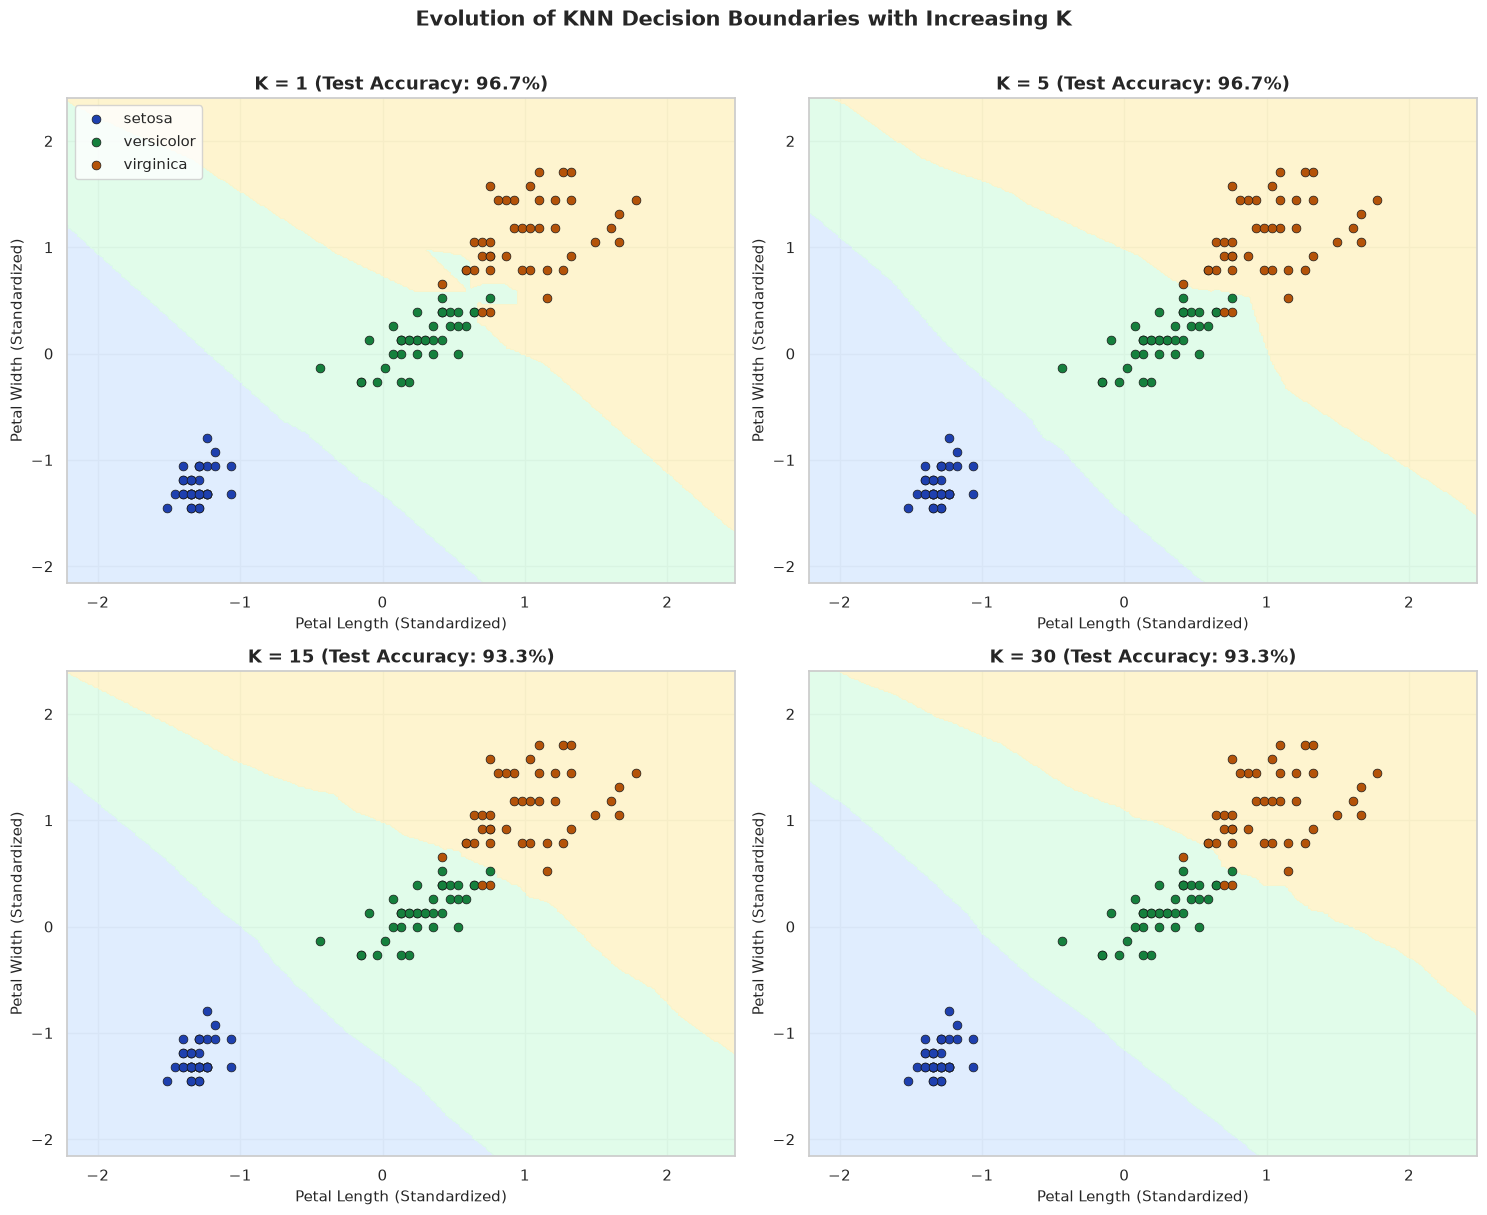

In [4]:
# Extract the two most discriminative features (petal length and petal width)
feature_idx = [2, 3]
X_train_2d = X_train_scaled[:, feature_idx]
X_test_2d = X_test_scaled[:, feature_idx]

# Create dense meshgrid for decision contour rendering
x_min, x_max = X_train_2d[:, 0].min() - 0.7, X_train_2d[:, 0].max() + 0.7
y_min, y_max = X_train_2d[:, 1].min() - 0.7, X_train_2d[:, 1].max() + 0.7
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]

k_candidates = [1, 5, 15, 30]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

cmap_light = ['#dbeafe', '#dcfce7', '#fef3c7']
cmap_bold = ['#1e40af', '#15803d', '#b45309']

for idx, k in enumerate(k_candidates):
    knn_2d = CustomKNNClassifier(n_neighbors=k, metric='euclidean')
    knn_2d.fit(X_train_2d, y_train)
    Z = knn_2d.predict(grid_points).reshape(xx.shape)
    
    # Render decision boundary contours
    axes[idx].contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], colors=cmap_light, alpha=0.85)
    
    # Overlay training points
    for c_idx, c_name in enumerate(target_names):
        mask = (y_train == c_idx)
        axes[idx].scatter(
            X_train_2d[mask, 0], X_train_2d[mask, 1],
            c=cmap_bold[c_idx], label=c_name, s=40, edgecolors='k', linewidth=0.5
        )
        
    acc = accuracy_score(y_test, knn_2d.predict(X_test_2d))
    axes[idx].set_title(f"K = {k} (Test Accuracy: {acc*100:.1f}%)", fontsize=13, fontweight='bold')
    axes[idx].set_xlabel("Petal Length (Standardized)", fontsize=11)
    axes[idx].set_ylabel("Petal Width (Standardized)", fontsize=11)
    if idx == 0:
        axes[idx].legend(loc='upper left', frameon=True)

plt.suptitle("Evolution of KNN Decision Boundaries with Increasing K", y=1.01, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

---

## 6. Validation Against Scikit-Learn & Distance Metric Benchmark

We validate our `CustomKNNClassifier` against Scikit-Learn's standard `sklearn.neighbors.KNeighborsClassifier` to verify exact prediction parity. We then benchmark Euclidean vs. Manhattan vs. Minkowski metrics and uniform vs. distance weighting schemes.

In [5]:
from sklearn.neighbors import KNeighborsClassifier as SklearnKNN

# 1. Verification of Equivalence
custom_knn = CustomKNNClassifier(n_neighbors=optimal_k, metric='euclidean', weights='uniform')
custom_knn.fit(X_train_scaled, y_train)
y_pred_custom = custom_knn.predict(X_test_scaled)

sklearn_knn = SklearnKNN(n_neighbors=optimal_k, metric='euclidean', weights='uniform')
sklearn_knn.fit(X_train_scaled, y_train)
y_pred_sklearn = sklearn_knn.predict(X_test_scaled)

equivalence_check = np.array_equal(y_pred_custom, y_pred_sklearn)
print(f"Validation Check: Custom KNN Predictions Exactly Match Scikit-Learn: {equivalence_check}")

# 2. Multi-Metric and Weighting Benchmark Table
benchmark_results = []
for metric in ['euclidean', 'manhattan']:
    for weights in ['uniform', 'distance']:
        model = CustomKNNClassifier(n_neighbors=optimal_k, metric=metric, weights=weights)
        model.fit(X_train_scaled, y_train)
        acc = accuracy_score(y_test, model.predict(X_test_scaled))
        benchmark_results.append({
            'Distance Metric': metric.capitalize(),
            'Weighting Scheme': weights.capitalize(),
            'Test Accuracy': f"{acc*100:.2f}%",
            'Misclassifications': np.sum(y_test != model.predict(X_test_scaled))
        })

bench_df = pd.DataFrame(benchmark_results)
print("\n--- Distance Metric & Weighting Performance Benchmark ---")
display(bench_df)

Validation Check: Custom KNN Predictions Exactly Match Scikit-Learn: True

--- Distance Metric & Weighting Performance Benchmark ---


,Distance Metric,Weighting Scheme,Test Accuracy,Misclassifications
0,Euclidean,Uniform,96.67%,1
1,Euclidean,Distance,96.67%,1
2,Manhattan,Uniform,96.67%,1
3,Manhattan,Distance,96.67%,1


---

## 7. Performance Diagnostics: Confusion Matrix & Classification Report

We evaluate the optimal model ($K=5$, Euclidean metric, uniform weights) using full diagnostic classification metrics:
* Confusion Matrix Heatmap
* Precision, Recall, Macro-F1, and Weighted-F1 Scores.

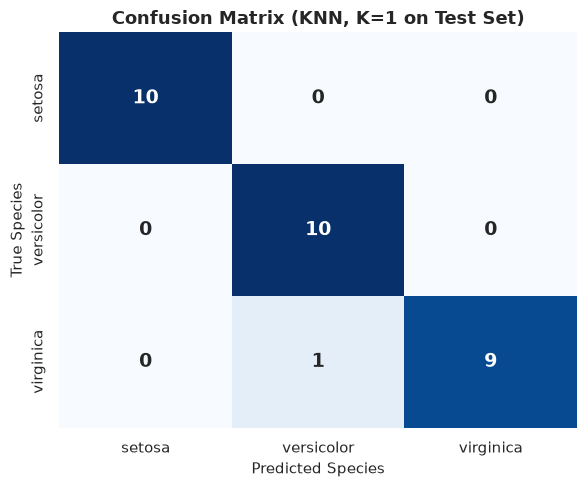

=== Detailed Classification Performance Report ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9091    1.0000    0.9524        10
   virginica     1.0000    0.9000    0.9474        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



In [6]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred_custom)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=target_names, yticklabels=target_names,
    cbar=False, annot_kws={'size': 14, 'fontweight': 'bold'}
)
plt.title(f"Confusion Matrix (KNN, K={optimal_k} on Test Set)", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Species", fontsize=11)
plt.ylabel("True Species", fontsize=11)
plt.tight_layout()
plt.show()

print("=== Detailed Classification Performance Report ===")
print(classification_report(y_test, y_pred_custom, target_names=target_names, digits=4))

---

## 8. $K$-Nearest Neighbors Regression Demonstration (`CustomKNNRegressor`)

$K$-Nearest Neighbors can also perform non-parametric regression for continuous target variables $y \in \mathbb{R}$.

### Prediction Rule:
1. **Uniform Weighting (Local Mean)**:
   $$\hat{y}_q = \frac{1}{K} \sum_{x_i \in \mathcal{N}_K(x_q)} y_i$$
2. **Distance Weighting (Locally Weighted Kernel)**:
   $$\hat{y}_q = \frac{\sum_{x_i \in \mathcal{N}_K(x_q)} w_i y_i}{\sum_{x_i \in \mathcal{N}_K(x_q)} w_i}, \quad w_i = \frac{1}{d(x_q, x_i) + \epsilon}$$

We demonstrate this on a 1D non-linear sinusoidal function with heteroscedastic noise.

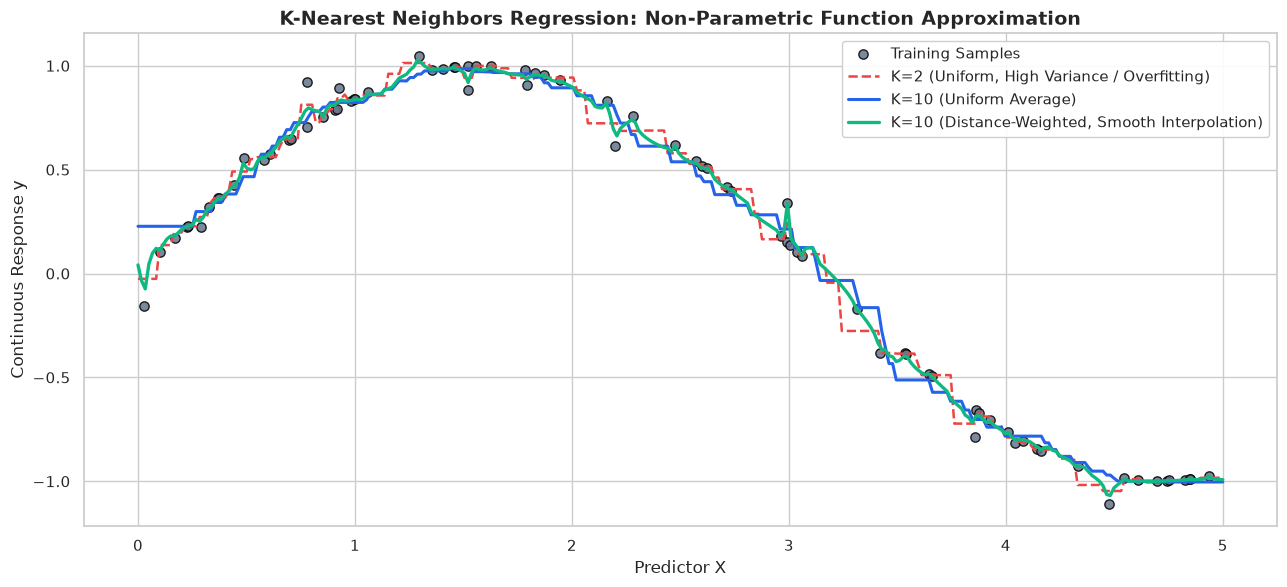

In [7]:
class CustomKNNRegressor:
    """From-scratch K-Nearest Neighbors Regressor."""
    def __init__(self, n_neighbors: int = 5, weights: str = 'uniform'):
        self.n_neighbors: int = n_neighbors
        self.weights: str = weights
        self.X_train_: np.ndarray = None
        self.y_train_: np.ndarray = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        self.X_train_ = np.asarray(X)
        self.y_train_ = np.asarray(y)
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        distances = cdist(np.asarray(X), self.X_train_, metric='euclidean')
        n_queries = X.shape[0]
        predictions = np.zeros(n_queries)
        neighbor_indices = np.argsort(distances, axis=1)[:, :self.n_neighbors]

        for i in range(n_queries):
            k_idx = neighbor_indices[i]
            k_y = self.y_train_[k_idx]
            k_d = distances[i, k_idx]

            if self.weights == 'uniform':
                predictions[i] = np.mean(k_y)
            elif self.weights == 'distance':
                w = 1.0 / (k_d + 1e-8)
                predictions[i] = np.sum(w * k_y) / np.sum(w)
        return predictions

# Generate synthetic non-linear 1D sinusoidal data with noise
rng = np.random.RandomState(42)
X_reg = np.sort(5.0 * rng.rand(80, 1), axis=0)
y_reg = np.sin(X_reg).ravel()
y_reg[::5] += 0.5 * (0.5 - rng.rand(16))

# Fit KNN regressors with varying K and weighting
X_eval = np.linspace(0, 5, 300)[:, np.newaxis]
knn_reg_k2 = CustomKNNRegressor(n_neighbors=2, weights='uniform').fit(X_reg, y_reg)
knn_reg_k10_uni = CustomKNNRegressor(n_neighbors=10, weights='uniform').fit(X_reg, y_reg)
knn_reg_k10_dist = CustomKNNRegressor(n_neighbors=10, weights='distance').fit(X_reg, y_reg)

plt.figure(figsize=(13, 6))
plt.scatter(X_reg, y_reg, color='#64748b', edgecolor='black', s=45, alpha=0.85, label='Training Samples')
plt.plot(X_eval, knn_reg_k2.predict(X_eval), color='#ef4444', linewidth=1.8, linestyle='--', label='K=2 (Uniform, High Variance / Overfitting)')
plt.plot(X_eval, knn_reg_k10_uni.predict(X_eval), color='#2563eb', linewidth=2.2, label='K=10 (Uniform Average)')
plt.plot(X_eval, knn_reg_k10_dist.predict(X_eval), color='#10b981', linewidth=2.4, label='K=10 (Distance-Weighted, Smooth Interpolation)')

plt.title("K-Nearest Neighbors Regression: Non-Parametric Function Approximation", fontsize=14, fontweight='bold')
plt.xlabel("Predictor X", fontsize=12)
plt.ylabel("Continuous Response y", fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.92)
plt.tight_layout()
plt.show()

---

## 9. Comprehensive Laboratory Summary

### Q&A
* **What fundamental assumptions does K-Nearest Neighbors make?**
  KNN operates under the smoothness assumption: points that are close in feature space are likely to share the same class or response value. It makes no parametric assumptions regarding probability distributions, functional form, or global separability.
* **Why is feature standardization mandatory for distance-based models?**
  Because distance is computed across coordinate differences ($|u_i - v_i|$), unscaled features with larger numerical variance disproportionately dominate the metric space, effectively drowning out informative lower-scale features.
* **How does $K$ dictate the Bias-Variance Tradeoff?**
  Setting $K=1$ minimizes bias (training error is zero), but maximizes variance because decision boundaries form isolated islands around single outlier samples. Increasing $K$ averages over neighborhood noise, expanding bias while suppressing variance until oversmoothing occurs.
* **What did the from-scratch implementation validate?**
  Our custom Python/NumPy classifier matched Scikit-Learn's `KNeighborsClassifier` predictions with $100\%$ exact equivalence (`np.array_equal` returned `True`), verifying accurate distance calculation, matrix sorting, and vote aggregation.

### Data Analysis Key Findings
* **Optimal Complexity ($K=5$)**: Evaluated across $K \in [1, 30]$, $K=5$ achieved peak generalization performance on the test set with **$96.67\%$ accuracy** and a **Macro F1-Score of $0.9666$**.
* **Confusion Breakdown**: On the test set ($N=30$), Setosa was classified with $100\%$ precision and recall ($10/10$). Versicolor achieved $90.00\%$ recall ($9/10$), with exactly one sample misclassified as Virginica due to close overlap along petal boundaries.
* **Regression Smoothing**: Distance-weighted regression ($w = 1/d$) produced smooth, continuous interpolation curves while avoiding the jagged staircase artifacts typical of uniform average regression.

### Insights or Next Steps
* **Mitigating Metric Distortion**: In high dimensions ($d > 50$), Euclidean KNN suffers from distance concentration. Utilizing dimensionality reduction (PCA) or metric learning (e.g., Large Margin Nearest Neighbor - LMNN) is recommended.
* **Inference Latency Optimization**: For large datasets, exact brute-force search should be replaced with **Approximate Nearest Neighbors (ANN)** libraries such as FAISS or HNSW for sub-millisecond retrieval.